# 01 Data Inspection — WM-811K

Goal: load the raw pickle, understand its structure, and record the key numbers (counts, label distribution, wafer map sizes).

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Old pickle (pandas 0.x) references `pandas.indexes`; alias it for pandas 2.x
import pandas.core.indexes
sys.modules["pandas.indexes"] = pandas.core.indexes

DATA_DIR = Path("../data")
RAW_PATH = DATA_DIR / "LSWMD.pkl"
CLEAN_PATH = DATA_DIR / "LSWMD_clean.pkl"

print(sys.version)
print("pandas", pd.__version__, "| numpy", np.__version__)

3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]
pandas 2.2.3 | numpy 2.1.2


In [2]:
%%time
# Load the cleaned copy if it exists, otherwise the raw pickle (slow, ~2GB)
if CLEAN_PATH.exists():
    df = pd.read_pickle(CLEAN_PATH)
    print("Loaded cleaned copy")
else:
    df = pd.read_pickle(RAW_PATH)
    print("Loaded raw pickle")

Loaded raw pickle
CPU times: total: 1min 57s
Wall time: 1min 58s


## 1. Basic structure

In [3]:
print("shape:", df.shape)
print("columns:", list(df.columns))
df.info(memory_usage="deep")
df.head()

shape: (811457, 6)
columns: ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 628.9 MB


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [4]:
# Inspect how the label columns are stored (often nested arrays like [['none']])
for col in df.columns:
    if col == "waferMap":
        continue
    v = df[col].iloc[0]
    print(f"{col:15s} type={type(v).__name__:10s} value={v!r}")

dieSize         type=float64    value=np.float64(1683.0)
lotName         type=str_       value=np.str_('lot1')
waferIndex      type=float64    value=np.float64(1.0)
trianTestLabel  type=ndarray    value=array([['Training']], dtype='<U8')
failureType     type=ndarray    value=array([['none']], dtype='<U4')


## 2. Flatten label columns

Note: the original dataset spells the split column `trianTestLabel` (typo). We rename it to `trainTestLabel`.

In [5]:
def flatten_label(x, empty="unlabeled"):
    """Turn nested arrays like [['none']] into 'none'; empty arrays into `empty`."""
    if isinstance(x, str):
        return x
    a = np.asarray(x).ravel()
    return str(a[0]) if a.size else empty

df = df.rename(columns={"trianTestLabel": "trainTestLabel"})
df["failureType"] = df["failureType"].apply(flatten_label)
df["trainTestLabel"] = df["trainTestLabel"].apply(flatten_label)

df[["lotName", "waferIndex", "dieSize", "failureType", "trainTestLabel"]].head()

,lotName,waferIndex,dieSize,failureType,trainTestLabel
0,lot1,1.0,1683.0,none,Training
1,lot1,2.0,1683.0,none,Training
2,lot1,3.0,1683.0,none,Training
3,lot1,4.0,1683.0,none,Training
4,lot1,5.0,1683.0,none,Training


## 3. Label distribution

In [6]:
ft = df["failureType"].value_counts()
print(ft, "\n")

n_total = len(df)
n_unlabeled = (df["failureType"] == "unlabeled").sum()
n_normal = (df["failureType"] == "none").sum()
n_defect = n_total - n_unlabeled - n_normal
n_labeled = n_normal + n_defect

print(f"Total      : {n_total:,}")
print(f"Unlabeled  : {n_unlabeled:,} ({n_unlabeled / n_total:.1%})")
print(f"Labeled    : {n_labeled:,}")
print(f"  Normal   : {n_normal:,} ({n_normal / n_labeled:.2%} of labeled)")
print(f"  Defect   : {n_defect:,} ({n_defect / n_labeled:.2%} of labeled)")
print(f"  Ratio    : 1 : {n_normal / n_defect:.1f} (defect : normal)")

failureType
unlabeled    638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64 

Total      : 811,457
Unlabeled  : 638,507 (78.7%)
Labeled    : 172,950
  Normal   : 147,431 (85.24% of labeled)
  Defect   : 25,519 (14.76% of labeled)
  Ratio    : 1 : 5.8 (defect : normal)


In [7]:
# Cross-tab: failure type vs. original train/test split
pd.crosstab(df["failureType"], df["trainTestLabel"], margins=True)

trainTestLabel,Test,Training,unlabeled,All
failureType,,,,
Center,832,3462,0,4294
Donut,146,409,0,555
Edge-Loc,2772,2417,0,5189
Edge-Ring,1126,8554,0,9680
Loc,1973,1620,0,3593
Near-full,95,54,0,149
Random,257,609,0,866
Scratch,693,500,0,1193
none,110701,36730,0,147431


## 4. Wafer map values and sizes

In [8]:
m0 = df["waferMap"].iloc[0]
print("type:", type(m0), "| dtype:", m0.dtype, "| shape:", m0.shape)
print("unique values (first map):", np.unique(m0))

# Unique pixel values over a sample of maps (full scan is slow)
sample = df["waferMap"].sample(5000, random_state=0)
print("unique values (5k sample):", np.unique(np.concatenate([np.unique(m) for m in sample])))

type: <class 'numpy.ndarray'> | dtype: uint8 | shape: (45, 48)
unique values (first map): [0 1 2]
unique values (5k sample): [0 1 2]


In [9]:
%%time
df["mapShape"] = df["waferMap"].apply(lambda m: m.shape)
df["mapH"] = df["mapShape"].str[0]
df["mapW"] = df["mapShape"].str[1]

print("distinct shapes:", df["mapShape"].nunique())
print(f"H range: {df['mapH'].min()} – {df['mapH'].max()}")
print(f"W range: {df['mapW'].min()} – {df['mapW'].max()}")
print("\nTop 10 most common shapes:")
print(df["mapShape"].value_counts().head(10))

distinct shapes: 632
H range: 6 – 300
W range: 3 – 205

Top 10 most common shapes:
mapShape
(32, 29)    108687
(25, 27)     64083
(49, 39)     39323
(26, 26)     30078
(30, 34)     29513
(33, 33)     23886
(33, 29)     20276
(39, 37)     15327
(52, 59)     14812
(31, 31)     14569
Name: count, dtype: int64
CPU times: total: 2.19 s
Wall time: 2.18 s


In [10]:
# Shape stats restricted to labeled data (what we will actually model)
labeled = df[df["failureType"] != "unlabeled"]
print("labeled distinct shapes:", labeled["mapShape"].nunique())
print(labeled[["mapH", "mapW", "dieSize"]].describe())

labeled distinct shapes: 346
                mapH           mapW        dieSize
count  172950.000000  172950.000000  172950.000000
mean       35.232807      34.822128    1042.232374
std        11.096015      11.876781    1032.572449
min        15.000000       3.000000       3.000000
25%        27.000000      27.000000     533.000000
50%        33.000000      33.000000     776.000000
75%        41.000000      40.000000    1250.000000
max       212.000000     204.000000   22372.000000


## 5. Visual check: one normal + one of each defect type

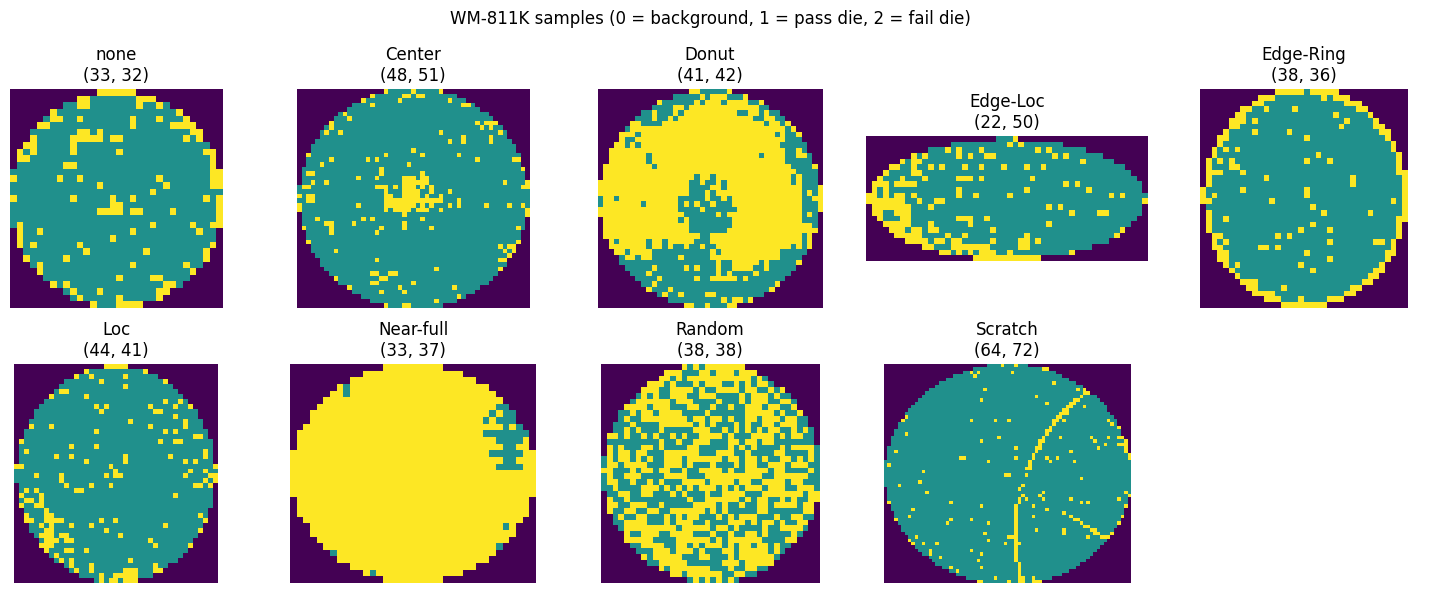

In [11]:
types = ["none"] + sorted(t for t in df["failureType"].unique() if t not in ("none", "unlabeled"))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, t in zip(axes.ravel(), types):
    row = df[df["failureType"] == t].sample(1, random_state=0).iloc[0]
    ax.imshow(row["waferMap"], cmap="viridis", vmin=0, vmax=2)
    ax.set_title(f"{t}\n{row['waferMap'].shape}")
    ax.axis("off")
for ax in axes.ravel()[len(types):]:
    ax.axis("off")
plt.suptitle("WM-811K samples (0 = background, 1 = pass die, 2 = fail die)")
plt.tight_layout()
plt.show()

## 6. Save a cleaned copy (pandas 2.x format, flattened labels)

In [12]:
%%time
if not CLEAN_PATH.exists():
    df.drop(columns=["mapShape"]).to_pickle(CLEAN_PATH)
    print("Saved", CLEAN_PATH)
else:
    print("Already exists:", CLEAN_PATH)

Saved ..\achieve\LSWMD_clean.pkl
CPU times: total: 27.1 s
Wall time: 28.3 s
